# TF / IDF Normalization Comparison for Language Identification
### Introduction to Large Language Models — Assignment 2

This notebook reuses the **exact same dataset** built in Assignment 1 (IndicCorp v2, 23
languages, 1000 sentences each, 80/10/10 stratified train/val/test split — loaded from
`splits/train.parquet`, `splits/val.parquet`, `splits/test.parquet`).

We implement two kinds of TF normalization, one IDF normalization, and compare all
**6 combinations** of {TF variant} × {IDF variant} using the same from-scratch softmax logistic
regression and macro-F1 evaluation as Assignment 1 (again, no `sklearn` classes anywhere).

**TF variants** — let $\text{tf}(t,d)$ be the raw count of term $t$ in sentence $d$:

$$TF_{UN}(t,d) = \ln(1 + \text{tf}(t,d)) + 1 \qquad \text{(unnormalized — log-scaled raw count)}$$

$$TF_{NT_1}(t,d) = \frac{\text{tf}(t,d)}{\sum_{t'} \text{tf}(t',d)} \qquad \text{(normalized by total number of words in the sentence)}$$

$$TF_{NT_2}(t,d) = \frac{\text{tf}(t,d)}{\max_{t'} \text{tf}(t',d)} \qquad \text{(normalized by frequency of the most frequent word in the sentence)}$$

**IDF variants** — let $n_t$ be the number of training sentences containing $t$ (document
frequency), $N$ the total number of training sentences, and $n_{t,\max} = \max_{t'} n_{t'}$ the
document frequency of the single most frequent term in the training vocabulary:

$$IDF_{UN}(t) = \ln\!\left(\frac{N+1}{n_t+1}\right) + 1 \qquad \text{(unnormalized)}$$

$$IDF_{NI_1}(t) = \ln\!\left(\frac{n_{t,\max}+1}{n_t+1}\right) + 1 \qquad \text{(normalized by the document frequency of the most frequent word across sentences)}$$

**Six models** (TF × IDF combination), matching the assignment's numbering:

| Model | TF    | IDF  |
|-------|-------|------|
| 1     | UN    | UN   |
| 2     | NT1   | UN   |
| 3     | NT2   | UN   |
| 4     | UN    | NI1  |
| 5     | NT1   | NI1  |
| 6     | NT2   | NI1  |

Each variant's raw-count features are the **same word-unigram/bigram + character 2/3/4-gram
feature space** used in Assignment 1 (word tokens via a Unicode-aware tokenizer, so "word" in the
TF formulas above is this combined word+character feature space, not literal whitespace-split
words alone).


## 0. Setup

In [1]:
%pip install -q pandas pyarrow numpy scipy regex tqdm matplotlib


Note: you may need to restart the kernel to use updated packages.


In [4]:
import os
import itertools
import pickle
from collections import Counter

import numpy as np
import pandas as pd
from scipy import sparse
import regex  # unicode-aware \p{L}/\p{M} classes -- keeps Indic conjuncts intact
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

SPLITS_DIR = "/Users/vatsalbateriwala/Developer/sem 7/ILLM Lab/Lab-1/splits"          # written by the Assignment 1 notebook
ARTIFACTS_DIR = "/Users/vatsalbateriwala/Developer/sem 7/ILLM Lab/Lab-2/artifacts_normalization"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)


## 1. Load the Assignment 1 dataset

This reuses `splits/train.parquet`, `splits/val.parquet`, `splits/test.parquet` exactly as
written by the Assignment 1 notebook — run that notebook first (through §4) if these aren't
present yet.


In [5]:
def _load_split(name):
    path = os.path.join(SPLITS_DIR, f"{name}.parquet")
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Couldn't find {path}. Run the Assignment 1 notebook first (through \u00a74, "
            f"'Stratified train/validation/test split') so it writes splits/train.parquet, "
            f"splits/val.parquet, and splits/test.parquet."
        )
    return pd.read_parquet(path)

train_df = _load_split("train")
val_df = _load_split("val")
test_df = _load_split("test")

LABELS = sorted(train_df["label"].unique())
LABEL2IDX = {lab: i for i, lab in enumerate(LABELS)}
IDX2LABEL = {i: lab for lab, i in LABEL2IDX.items()}

y_train = train_df["label"].map(LABEL2IDX).to_numpy()
y_val = val_df["label"].map(LABEL2IDX).to_numpy()
y_test = test_df["label"].map(LABEL2IDX).to_numpy()

print(f"{len(LABELS)} languages")
print("train:", train_df.shape, " val:", val_df.shape, " test:", test_df.shape)


23 languages
train: (18400, 4)  val: (2300, 4)  test: (2300, 4)


## 2. Feature space (same as Assignment 1)

Word unigrams + bigrams (Unicode-aware tokenizer) and character 2/3/4-grams, combined into one
feature space. This is identical to Assignment 1 — only the TF/IDF *weighting* changes below.


In [6]:
_WORD_RE = regex.compile(r"[\p{L}\p{M}]+|\p{N}+", regex.UNICODE)

def word_tokenize(sentence):
    return _WORD_RE.findall(sentence)

def char_ngrams(sentence, n):
    s = sentence.replace(" ", "\u2581")
    s = "\u2581" + s + "\u2581"
    if len(s) < n:
        return []
    return [s[i:i + n] for i in range(len(s) - n + 1)]

def extract_features(sentence):
    words = word_tokenize(sentence)
    feats = []
    feats.extend("W1_" + w for w in words)
    feats.extend("W2_" + words[i] + "_" + words[i + 1] for i in range(len(words) - 1))
    for n in (2, 3, 4):
        feats.extend(f"C{n}_" + g for g in char_ngrams(sentence, n))
    return feats


## 3. Custom count vectorizer (raw counts only)

All 6 TF/IDF combinations are *derived* from one shared raw-count representation, so feature
extraction and vocabulary selection (by training-set document frequency, capped at
`max_features`) happen exactly once — the 6 combinations only differ in cheap sparse-matrix
arithmetic on top of these counts. Vocabulary/IDF statistics are fit **only on the training set**.


In [7]:
class CustomCountVectorizer:
    def __init__(self, max_features=60000, min_df=2):
        self.max_features = max_features
        self.min_df = min_df
        self.vocab_ = {}
        self.df_ = None     # document frequency per vocab term (on the fit/train corpus)
        self.n_docs_ = 0

    def fit(self, texts):
        doc_feats = [extract_features(t) for t in tqdm(texts, desc="fit: extracting features", leave=False)]
        df_counts = Counter()
        for feats in doc_feats:
            for f in set(feats):
                df_counts[f] += 1
        df_counts = {f: c for f, c in df_counts.items() if c >= self.min_df}

        top = sorted(df_counts.items(), key=lambda x: (-x[1], x[0]))[:self.max_features]
        self.vocab_ = {f: i for i, (f, _) in enumerate(top)}
        self.df_ = np.array([df_counts[f] for f, _ in top], dtype=np.float64)
        self.n_docs_ = len(texts)
        print(f"Vocabulary size: {len(self.vocab_)}")
        return self

    def transform_counts(self, texts, desc="transforming"):
        rows, cols, data = [], [], []
        for r, text in enumerate(tqdm(texts, desc=desc, leave=False)):
            counts = Counter(extract_features(text))
            for f, c in counts.items():
                j = self.vocab_.get(f)
                if j is None:
                    continue
                rows.append(r); cols.append(j); data.append(float(c))
        return sparse.csr_matrix((data, (rows, cols)), shape=(len(texts), len(self.vocab_)))


In [8]:
cv = CustomCountVectorizer(max_features=60000, min_df=2)
cv.fit(train_df["text"].tolist())

Xc_train = cv.transform_counts(train_df["text"].tolist(), desc="counts (train)")
Xc_val = cv.transform_counts(val_df["text"].tolist(), desc="counts (val)")
Xc_test = cv.transform_counts(test_df["text"].tolist(), desc="counts (test)")

print("Xc_train:", Xc_train.shape, " Xc_val:", Xc_val.shape, " Xc_test:", Xc_test.shape)


Vocabulary size: 60000


Xc_train: (18400, 60000)  Xc_val: (2300, 60000)  Xc_test: (2300, 60000)


## 4. TF and IDF normalization functions (exact formulas above)

In [9]:
def apply_tf(X_counts, mode):
    """mode in {'UN', 'NT1', 'NT2'}. Only stored (nonzero) entries are transformed, so terms
    absent from a sentence stay exactly 0 -- this preserves sparsity for every variant,
    including UN's log transform (ln(1+0)+1 would otherwise be 1, densifying every vector)."""
    X = X_counts.tocsr(copy=True)
    if mode == "UN":
        X.data = np.log1p(X.data) + 1.0
        return X
    elif mode == "NT1":
        row_sum = np.asarray(X.sum(axis=1)).ravel()
        row_sum[row_sum == 0] = 1.0
        return X.multiply(1.0 / row_sum[:, None]).tocsr()
    elif mode == "NT2":
        row_max = X.max(axis=1).toarray().ravel()
        row_max[row_max == 0] = 1.0
        return X.multiply(1.0 / row_max[:, None]).tocsr()
    else:
        raise ValueError(f"unknown TF mode {mode!r}")


def compute_idf(df, n_docs, mode):
    """mode in {'UN', 'NI1'}. df and n_docs are always computed on the TRAINING set only."""
    if mode == "UN":
        return np.log((n_docs + 1) / (df + 1)) + 1.0
    elif mode == "NI1":
        nt_max = df.max()
        return np.log((nt_max + 1) / (df + 1)) + 1.0
    else:
        raise ValueError(f"unknown IDF mode {mode!r}")


def l2_normalize(X):
    norms = np.sqrt(np.asarray(X.multiply(X).sum(axis=1)).ravel())
    norms[norms == 0] = 1.0
    return X.multiply(1.0 / norms[:, None]).tocsr()


def build_tfidf(X_counts, df, n_docs, tf_mode, idf_mode):
    """Combine a TF variant with an IDF variant, then L2-row-normalize. The final
    normalization is applied identically to all 6 combinations so the comparison isolates the
    effect of the TF/IDF weighting scheme rather than raw vector magnitude."""
    TF = apply_tf(X_counts, tf_mode)
    IDF = compute_idf(df, n_docs, idf_mode)
    X = TF.multiply(IDF[None, :]).tocsr()
    return l2_normalize(X)


## 5. Custom multinomial (softmax) logistic regression & macro-F1 (same as Assignment 1)

In [10]:
class SoftmaxLogisticRegression:
    def __init__(self, n_features, n_classes, lr=0.5, l2=1e-5, epochs=20, batch_size=256,
                 seed=RANDOM_SEED, verbose=False):
        rng = np.random.default_rng(seed)
        self.W = rng.normal(0, 0.01, size=(n_features, n_classes))
        self.b = np.zeros(n_classes)
        self.lr = lr
        self.l2 = l2
        self.epochs = epochs
        self.batch_size = batch_size
        self.verbose = verbose
        self.history = {"train_loss": [], "val_macro_f1": []}

    @staticmethod
    def _softmax(Z):
        Z = Z - Z.max(axis=1, keepdims=True)
        expZ = np.exp(Z)
        return expZ / expZ.sum(axis=1, keepdims=True)

    def _forward(self, X):
        return self._softmax(X.dot(self.W) + self.b)

    def fit(self, X, y, X_val=None, y_val=None, eval_fn=None):
        n_samples = X.shape[0]
        n_classes = self.W.shape[1]
        Y = np.zeros((n_samples, n_classes))
        Y[np.arange(n_samples), y] = 1.0
        rng = np.random.default_rng(RANDOM_SEED)

        for epoch in range(1, self.epochs + 1):
            perm = rng.permutation(n_samples)
            total_loss = 0.0
            for start in range(0, n_samples, self.batch_size):
                idx = perm[start:start + self.batch_size]
                Xb, Yb = X[idx], Y[idx]
                P = self._forward(Xb)
                eps = 1e-12
                batch_loss = -np.sum(Yb * np.log(P + eps)) / Xb.shape[0]
                batch_loss += 0.5 * self.l2 * np.sum(self.W ** 2)
                total_loss += batch_loss * Xb.shape[0]

                grad_Z = (P - Yb) / Xb.shape[0]
                grad_W = Xb.T.dot(grad_Z) + self.l2 * self.W
                grad_b = grad_Z.sum(axis=0)
                self.W -= self.lr * grad_W
                self.b -= self.lr * grad_b

            avg_loss = total_loss / n_samples
            self.history["train_loss"].append(avg_loss)
            msg = f"epoch {epoch:3d}/{self.epochs}  train_loss={avg_loss:.4f}"
            if X_val is not None and y_val is not None and eval_fn is not None:
                val_pred = self.predict(X_val)
                val_mf1, _ = eval_fn(y_val, val_pred)
                self.history["val_macro_f1"].append(val_mf1)
                msg += f"  val_macro_f1={val_mf1:.4f}"
            if self.verbose:
                print(msg)
        return self

    def predict_proba(self, X):
        return self._forward(X)

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)


def precision_recall_f1_per_class(y_true, y_pred, n_classes):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    precisions, recalls, f1s = [], [], []
    for c in range(n_classes):
        tp = np.sum((y_pred == c) & (y_true == c))
        fp = np.sum((y_pred == c) & (y_true != c))
        fn = np.sum((y_pred != c) & (y_true == c))
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) > 0 else 0.0
        precisions.append(precision); recalls.append(recall); f1s.append(f1)
    return np.array(precisions), np.array(recalls), np.array(f1s)

def macro_f1_score(y_true, y_pred, n_classes):
    _, _, f1s = precision_recall_f1_per_class(y_true, y_pred, n_classes)
    return float(np.mean(f1s)), f1s

def accuracy_score_custom(y_true, y_pred):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    return float(np.mean(y_true == y_pred))


## 6. Train and evaluate all 6 TF × IDF combinations

Each combination gets its own freshly-initialized classifier (same hyperparameters, same random
seed, same epoch budget) trained on that combination's TF-IDF matrix, then evaluated on the held-out
test set with macro-F1 — exactly the Assignment 1 evaluation protocol.


In [11]:
N_CLASSES = len(LABELS)
N_FEATURES = len(cv.vocab_)
EPOCHS = 20

MODEL_TABLE = [
    ("Model 1", "UN",  "UN"),
    ("Model 2", "NT1", "UN"),
    ("Model 3", "NT2", "UN"),
    ("Model 4", "UN",  "NI1"),
    ("Model 5", "NT1", "NI1"),
    ("Model 6", "NT2", "NI1"),
]

results = []
trained_models = {}

for model_name, tf_mode, idf_mode in MODEL_TABLE:
    print(f"\n=== {model_name}: TF={tf_mode}, IDF={idf_mode} ===")

    X_train = build_tfidf(Xc_train, cv.df_, cv.n_docs_, tf_mode, idf_mode)
    X_val = build_tfidf(Xc_val, cv.df_, cv.n_docs_, tf_mode, idf_mode)
    X_test = build_tfidf(Xc_test, cv.df_, cv.n_docs_, tf_mode, idf_mode)

    clf = SoftmaxLogisticRegression(n_features=N_FEATURES, n_classes=N_CLASSES,
                                     lr=0.5, l2=1e-5, epochs=EPOCHS, batch_size=256, verbose=False)
    eval_fn = lambda yt, yp: macro_f1_score(yt, yp, N_CLASSES)
    clf.fit(X_train, y_train, X_val=X_val, y_val=y_val, eval_fn=eval_fn)

    test_pred = clf.predict(X_test)
    test_acc = accuracy_score_custom(y_test, test_pred)
    test_mf1, _ = macro_f1_score(y_test, test_pred, N_CLASSES)

    print(f"{model_name}  test_accuracy={test_acc:.4f}  test_macro_f1={test_mf1:.4f}")

    results.append({
        "model": model_name, "tf": tf_mode, "idf": idf_mode,
        "val_macro_f1_final": clf.history["val_macro_f1"][-1] if clf.history["val_macro_f1"] else None,
        "test_accuracy": test_acc, "test_macro_f1": test_mf1,
    })
    trained_models[model_name] = clf

results_df = pd.DataFrame(results).set_index("model")
results_df.sort_values("test_macro_f1", ascending=False)



=== Model 1: TF=UN, IDF=UN ===
Model 1  test_accuracy=0.9383  test_macro_f1=0.9342

=== Model 2: TF=NT1, IDF=UN ===
Model 2  test_accuracy=0.9365  test_macro_f1=0.9323

=== Model 3: TF=NT2, IDF=UN ===
Model 3  test_accuracy=0.9365  test_macro_f1=0.9323

=== Model 4: TF=UN, IDF=NI1 ===
Model 4  test_accuracy=0.9413  test_macro_f1=0.9373

=== Model 5: TF=NT1, IDF=NI1 ===
Model 5  test_accuracy=0.9417  test_macro_f1=0.9376

=== Model 6: TF=NT2, IDF=NI1 ===
Model 6  test_accuracy=0.9417  test_macro_f1=0.9376


,tf,idf,val_macro_f1_final,test_accuracy,test_macro_f1
model,,,,,
Model 5,NT1,NI1,0.933529,0.941739,0.937600
Model 6,NT2,NI1,0.933529,0.941739,0.937600
Model 4,UN,NI1,0.938810,0.941304,0.937283
Model 1,UN,UN,0.937008,0.938261,0.934197
Model 2,NT1,UN,0.931130,0.936522,0.932309
Model 3,NT2,UN,0.931130,0.936522,0.932309


## 7. Compare results

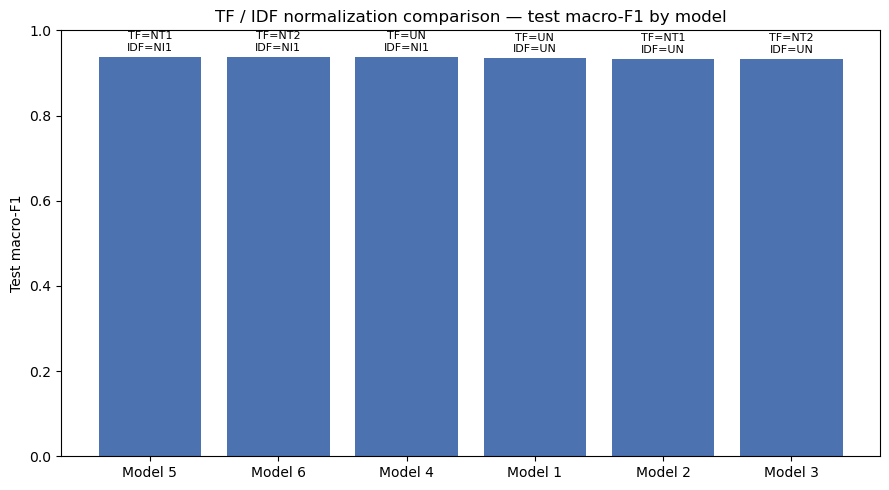

,tf,idf,val_macro_f1_final,test_accuracy,test_macro_f1
model,,,,,
Model 1,UN,UN,0.937008,0.938261,0.934197
Model 2,NT1,UN,0.931130,0.936522,0.932309
Model 3,NT2,UN,0.931130,0.936522,0.932309
Model 4,UN,NI1,0.938810,0.941304,0.937283
Model 5,NT1,NI1,0.933529,0.941739,0.937600
Model 6,NT2,NI1,0.933529,0.941739,0.937600


In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
order = results_df.sort_values("test_macro_f1", ascending=False)
bars = ax.bar(order.index, order["test_macro_f1"], color="#4C72B0")
ax.set_ylabel("Test macro-F1")
ax.set_title("TF / IDF normalization comparison — test macro-F1 by model")
ax.set_ylim(0, 1)
for bar, tf, idf in zip(bars, order["tf"], order["idf"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
            f"TF={tf}\nIDF={idf}", ha="center", va="bottom", fontsize=8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

results_df


In [13]:
best_model_name = results_df["test_macro_f1"].idxmax()
worst_model_name = results_df["test_macro_f1"].idxmin()
print(f"Best:  {best_model_name}  (TF={results_df.loc[best_model_name, 'tf']}, "
      f"IDF={results_df.loc[best_model_name, 'idf']})  "
      f"test_macro_f1={results_df.loc[best_model_name, 'test_macro_f1']:.4f}")
print(f"Worst: {worst_model_name}  (TF={results_df.loc[worst_model_name, 'tf']}, "
      f"IDF={results_df.loc[worst_model_name, 'idf']})  "
      f"test_macro_f1={results_df.loc[worst_model_name, 'test_macro_f1']:.4f}")


Best:  Model 5  (TF=NT1, IDF=NI1)  test_macro_f1=0.9376
Worst: Model 2  (TF=NT1, IDF=UN)  test_macro_f1=0.9323


In [17]:
def infer_new_texts(texts, show_all_probs=False):
    """Run every trained model on `texts` and print per-language
    probabilities and the final predicted label for each input."""
    # Convert texts to raw-count sparse matrix using the shared count vectorizer
    Xc_new = cv.transform_counts(texts, desc="counts (inference)")

    for model_name, tf_mode, idf_mode in MODEL_TABLE:
        print(f"\n=== {model_name}: TF={tf_mode}, IDF={idf_mode} ===")

        # Build TF-IDF for the new texts using the training-fit IDF statistics
        X_new = build_tfidf(Xc_new, cv.df_, cv.n_docs_, tf_mode, idf_mode)

        clf = trained_models[model_name]
        probs = clf.predict_proba(X_new)
        preds = np.argmax(probs, axis=1)

        for i, text in enumerate(texts):
            print(f" Input [{i+1}]: {text}")

            # Print probability for every language (in the original LABEL order)
            if show_all_probs:
                for cls_idx, prob in enumerate(probs[i]):
                    print(f"  {IDX2LABEL[cls_idx]:20s}: {prob:.4f}")
            else:
                # Print only top-3 if not showing all
                topk = np.argsort(probs[i])[::-1][:3]
                for cls_idx in topk:
                    print(f"  {IDX2LABEL[cls_idx]:20s}: {probs[i, cls_idx]:.4f}")

            final_idx = preds[i]
            print(f"--> Predicted: {IDX2LABEL[final_idx]}  (prob={probs[i, final_idx]:.4f})")

# Example usage: replace or extend `new_texts` with your own sentences
new_texts = [
    "यह एक परीक्षण वाक्य है।",
    "இங்க உக்காருங்க.",
]
infer_new_texts(new_texts)



=== Model 1: TF=UN, IDF=UN ===
 Input [1]: यह एक परीक्षण वाक्य है।
  hin_Deva            : 0.1061
  mai_Deva            : 0.0708
  npi_Deva            : 0.0663
--> Predicted: hin_Deva  (prob=0.1061)
 Input [2]: இங்க உக்காருங்க.
  tam_Taml            : 0.1781
  san_Deva            : 0.0442
  gom_Deva            : 0.0421
--> Predicted: tam_Taml  (prob=0.1781)

=== Model 2: TF=NT1, IDF=UN ===
 Input [1]: यह एक परीक्षण वाक्य है।
  hin_Deva            : 0.0963
  mai_Deva            : 0.0762
  san_Deva            : 0.0709
--> Predicted: hin_Deva  (prob=0.0963)
 Input [2]: இங்க உக்காருங்க.
  tam_Taml            : 0.2198
  san_Deva            : 0.0456
  mai_Deva            : 0.0428
--> Predicted: tam_Taml  (prob=0.2198)

=== Model 3: TF=NT2, IDF=UN ===
 Input [1]: यह एक परीक्षण वाक्य है।
  hin_Deva            : 0.0963
  mai_Deva            : 0.0762
  san_Deva            : 0.0709
--> Predicted: hin_Deva  (prob=0.0963)
 Input [2]: இங்க உக்காருங்க.
  tam_Taml            : 0.2198
  san_Deva      

## 8. Save results

In [14]:
results_df.to_csv(os.path.join(ARTIFACTS_DIR, "tfidf_normalization_comparison.csv"))

with open(os.path.join(ARTIFACTS_DIR, "trained_models.pkl"), "wb") as f:
    pickle.dump({name: {"W": m.W, "b": m.b, "history": m.history}
                 for name, m in trained_models.items()}, f)

with open(os.path.join(ARTIFACTS_DIR, "count_vectorizer.pkl"), "wb") as f:
    pickle.dump({"vocab": cv.vocab_, "df": cv.df_, "n_docs": cv.n_docs_,
                 "max_features": cv.max_features, "min_df": cv.min_df}, f)

print("Saved comparison table, trained model weights, and shared count vectorizer to",
      ARTIFACTS_DIR)


Saved comparison table, trained model weights, and shared count vectorizer to /Users/vatsalbateriwala/Developer/sem 7/ILLM Lab/Lab-2/artifacts_normalization
